In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df_clean = pd.read_csv("../data/cleaned_data.csv",dtype ={'InvoiceNo':str})

In [3]:
df_clean.dtypes


InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID         str
Country            str
dtype: object

In [4]:
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df_clean['Revenue'] = df_clean['Quantity']*df_clean['UnitPrice']

In [6]:
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [7]:
total_revenue = df_clean['Revenue'].sum()

In [8]:
total_revenue

np.float64(10642110.804000001)

In [9]:
df_clean['Description'].unique()

<ArrowStringArray>
[ 'WHITE HANGING HEART T-LIGHT HOLDER',                 'WHITE METAL LANTERN',
      'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE',
      'RED WOOLLY HOTTIE WHITE HEART.',        'SET 7 BABUSHKA NESTING BOXES',
   'GLASS STAR FROSTED T-LIGHT HOLDER',              'HAND WARMER UNION JACK',
           'HAND WARMER RED POLKA DOT',       'ASSORTED COLOUR BIRD ORNAMENT',
 ...
             'SNACK TRAY PAISLEY PARK',      'SET OF 6 RIBBONS COUNTRY STYLE',
        'SNACK TRAY RED VINTAGE DOILY', 'SET OF 6 RIBBONS PERFECTLY PRETTY  ',
              'SET OF 6 RIBBONS PARTY',      'SET 10 CARDS SNOWY ROBIN 17099',
 'SET 10 CARDS SWIRLY XMAS TREE 17104',           'LETTER "U" BLING KEY RING',
  'CREAM HANGING HEART T-LIGHT HOLDER',         'PAPER CRAFT , LITTLE BIRDIE']
Length: 4026, dtype: str

In [10]:
suspicious_keywords = ['POSTAGE', 'MANUAL', 'CHARGES', 'ADJUST', 'CARRIAGE', 'AMAZON', 'SAMPLES', 'DISCOUNT']
for word in suspicious_keywords:
    matches  = df_clean[df_clean['Description'].str.contains(word,case= False,na =False)]['Description'].unique()
    if len(matches)>0:
       print(f"Keyword '{word}' found in:", matches)

Keyword 'POSTAGE' found in: <ArrowStringArray>
['POSTAGE', 'DOTCOM POSTAGE']
Length: 2, dtype: str
Keyword 'MANUAL' found in: <ArrowStringArray>
['Manual']
Length: 1, dtype: str
Keyword 'CHARGES' found in: <ArrowStringArray>
['Bank Charges']
Length: 1, dtype: str
Keyword 'ADJUST' found in: <ArrowStringArray>
['Adjust bad debt']
Length: 1, dtype: str
Keyword 'CARRIAGE' found in: <ArrowStringArray>
[                    'CARRIAGE', 'BLACK BAROQUE CARRIAGE CLOCK',
      'FRENCH CARRIAGE LANTERN',            'Next Day Carriage']
Length: 4, dtype: str
Keyword 'AMAZON' found in: <ArrowStringArray>
['AMAZON FEE']
Length: 1, dtype: str
Keyword 'SAMPLES' found in: <ArrowStringArray>
['SAMPLES']
Length: 1, dtype: str


In [11]:
df_clean.shape

(524878, 9)

In [12]:
non_products = ['POSTAGE', 'DOTCOM POSTAGE', 'Manual', 'Bank Charges', 'Adjust bad debt', 'AMAZON FEE', 'SAMPLES', 'Next Day Carriage', 'CARRIAGE']

df_real_product = df_clean[~df_clean['Description'].str.strip().isin(non_products)]

print('DOTCOM POSTAGE' in df_real_product['Description'].values)
print(df_real_product.shape)

False
(522492, 9)


In [13]:
top_product_revenue = df_real_product.groupby('Description')['Revenue'].sum().sort_values(ascending=False)


In [14]:
top_product_revenue.head(10)

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Revenue, dtype: float64

In [15]:
df_clean['Quantity'].unique()

array([    6,     8,     2,    32,     3,     4,    24,    12,    48,
          18,    20,    36,    80,    64,    10,   120,    96,    23,
           5,     1,    50,    40,   100,   192,   432,   144,   288,
          16,     9,   128,    25,    30,    28,     7,    72,   200,
         600,   480,    14,    11,    33,    13,    70,   252,    60,
         216,   384,    27,    15,    22,    19,    17,    21,    34,
          47,   108,    52,    75,   270,    42,   240,    90,   320,
        1824,   204,    69,   160,  2880,  1400,    39,    56,    26,
        1440,    31,    82,    78,    97,    98,    35,   720,   156,
         324,    38,    37,    49,    95,    29,    41,   402,   378,
         150,   300,    54,   104,    67,   258,    66,    44,    55,
          46,    99,    61,   408,   972,   208,  1008,  1000,  1488,
         250,  1394,   400,   110,   272,    84,   113,    45,   106,
          68,   267,   115,    65,  1728,    53,    76,    71,    43,
         213,    58,

In [16]:
top_product_quantity = df_real_product.groupby('Description')['Quantity'].sum().sort_values(ascending =False)

In [17]:
top_product_quantity.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

In [18]:
df_clean['InvoiceDate'].info()

<class 'pandas.Series'>
RangeIndex: 524878 entries, 0 to 524877
Series name: InvoiceDate
Non-Null Count   Dtype
--------------   -----
524878 non-null  str  
dtypes: str(1)
memory usage: 13.5 MB


In [19]:
df_real_product['InvoiceDate'] = pd.to_datetime(df_real_product['InvoiceDate'])


In [20]:
df_clean['InvoiceDate'].dtype

<StringDtype(na_value=nan)>

In [21]:
df_time = df_real_product.set_index('InvoiceDate')
monthly_revenue = df_time['Revenue'].resample('ME').sum()

In [22]:
monthly_revenue.head(50)

InvoiceDate
2010-12-31     775714.950
2011-01-31     670439.460
2011-02-28     507866.540
2011-03-31     689841.840
2011-04-30     515469.661
2011-05-31     740021.330
2011-06-30     737533.990
2011-07-31     688087.671
2011-08-31     724173.160
2011-09-30    1028255.381
2011-10-31    1103210.920
2011-11-30    1451740.980
2011-12-31     614349.250
Freq: ME, Name: Revenue, dtype: float64

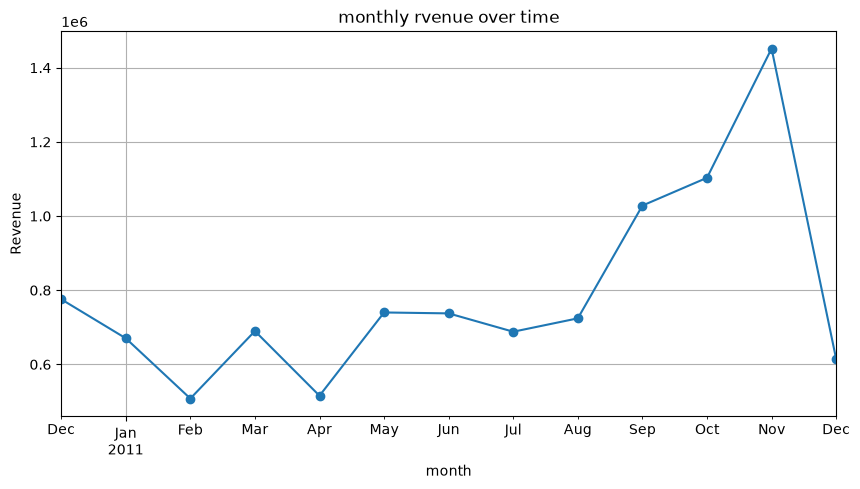

In [23]:
monthly_revenue.plot(kind = 'line',marker ='o',figsize =(10,5))
plt.title('monthly rvenue over time')
plt.xlabel('month')
plt.ylabel('Revenue')
plt.grid(True)
plt.show()

In [24]:
df_real_product['InvoiceDate'].max()

Timestamp('2011-12-09 12:50:00')

In [25]:
customer_revenue =df_real_product.groupby('CustomerID')['Revenue'].sum().sort_values(ascending =False)

In [26]:
customer_revenue.head()

CustomerID
unknown    1510677.49
14646.0     279138.02
18102.0     259657.30
17450.0     194390.79
16446.0     168472.50
Name: Revenue, dtype: float64

In [27]:
customer_revenue_real = customer_revenue[customer_revenue.index!= 'unknown']

In [28]:
customer_revenue_real.head(10)

CustomerID
14646.0    279138.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    136161.83
12415.0    124564.53
14156.0    116560.08
17511.0     91062.38
12346.0     77183.60
16029.0     72708.09
Name: Revenue, dtype: float64

In [29]:
revenue_by_country = df_real_product.groupby('Country')['Revenue'].sum().sort_values(ascending =False)

In [30]:
revenue_by_country.head(10)

Country
United Kingdom    8723929.483
Netherlands        283889.340
EIRE               270850.860
Germany            205381.150
France             184493.000
Australia          138103.810
Spain               55706.560
Switzerland         53065.600
Japan               37416.370
Belgium             36927.340
Name: Revenue, dtype: float64

In [31]:
monthly_growth = monthly_revenue.pct_change()* 100  

In [32]:
monthly_analysis = pd.DataFrame({'Revenue':monthly_revenue,'Growth_%':monthly_growth})

In [33]:
print(monthly_analysis)

                 Revenue   Growth_%
InvoiceDate                        
2010-12-31    775714.950        NaN
2011-01-31    670439.460 -13.571414
2011-02-28    507866.540 -24.248710
2011-03-31    689841.840  35.831323
2011-04-30    515469.661 -25.277124
2011-05-31    740021.330  43.562538
2011-06-30    737533.990  -0.336117
2011-07-31    688087.671  -6.704277
2011-08-31    724173.160   5.244316
2011-09-30   1028255.381  41.990264
2011-10-31   1103210.920   7.289584
2011-11-30   1451740.980  31.592332
2011-12-31    614349.250 -57.681897


In [34]:
monthly_analysis['Growth_%'] = monthly_analysis['Growth_%'].round(2)

In [35]:
print(monthly_analysis)

                 Revenue  Growth_%
InvoiceDate                       
2010-12-31    775714.950       NaN
2011-01-31    670439.460    -13.57
2011-02-28    507866.540    -24.25
2011-03-31    689841.840     35.83
2011-04-30    515469.661    -25.28
2011-05-31    740021.330     43.56
2011-06-30    737533.990     -0.34
2011-07-31    688087.671     -6.70
2011-08-31    724173.160      5.24
2011-09-30   1028255.381     41.99
2011-10-31   1103210.920      7.29
2011-11-30   1451740.980     31.59
2011-12-31    614349.250    -57.68


In [36]:
best_month =monthly_growth.idxmax()
best_value = monthly_growth.max()
worst_month = monthly_growth.idxmin()
worst_value = monthly_growth.min()

print(f"Best growth month: {best_month} with {best_value:.2f}% growth")
print(f"Worst growth month: {worst_month} with {worst_value:.2f}% decline")

Best growth month: 2011-05-31 00:00:00 with 43.56% growth
Worst growth month: 2011-12-31 00:00:00 with -57.68% decline


In [37]:
last_actual_date = df_real_product['InvoiceDate'].max()
latest_month_label = monthly_growth.index[-1]
is_incomplete = last_actual_date.day < latest_month_label.days_in_month

latest_growth = monthly_growth.iloc[-1]

if latest_growth > 0:
    print(f"📈 Revenue increased by {latest_growth:.2f}% compared with the previous month.")
elif latest_growth < 0:
    print(f"📉 Revenue decreased by {abs(latest_growth):.2f}% compared with the previous month.")
else:
    print("➡️ Revenue remained unchanged compared with the previous month.")

if is_incomplete:
    print(f"⚠️ Note: Data for {latest_month_label.strftime('%B %Y')} only goes up to {last_actual_date.strftime('%d %B')} — this month may be incomplete.")

📉 Revenue decreased by 57.68% compared with the previous month.
⚠️ Note: Data for December 2011 only goes up to 09 December — this month may be incomplete.


In [38]:
best_product = top_product_revenue.idxmax()
best_product_revenue = top_product_revenue.max()
best_product_quantity =top_product_quantity[best_product]  # look up its quantity too

print("Best product (by revenue):", best_product)
print("Revenue:", f"£{best_product_revenue:,.2f}")
print("Quantity sold:", f"{best_product_quantity:,}")

Best product (by revenue): REGENCY CAKESTAND 3 TIER
Revenue: £174,156.54
Quantity sold: 13,851


In [39]:
top_customer = customer_revenue_real.idxmax()
top_customer_spending = customer_revenue_real.max()

print("Top customer:", top_customer)
print("Spending:", top_customer_spending)

Top customer: 14646.0
Spending: 279138.02


In [40]:
average_customer_spending = customer_revenue_real.mean()

print("Average customer spending:", average_customer_spending)

Average customer spending: 2015.6962720350718


In [41]:
difference = top_customer_spending / average_customer_spending

print(f"Top customer spends {difference:.2f} times the average customer.")

Top customer spends 138.48 times the average customer.


In [42]:
best_country = revenue_by_country.idxmax()
best_country_revenue = revenue_by_country.max()

print("Best country:", best_country)
print("Revenue:", best_country_revenue)

Best country: United Kingdom
Revenue: 8723929.483000001


In [43]:
country_share = (
    best_country_revenue / total_revenue
) * 100

print(f"{best_country} contributes {country_share:.2f}% of total revenue.")

United Kingdom contributes 81.98% of total revenue.


In [44]:
mean_revenue = monthly_revenue.mean()

In [45]:
std_revenue = monthly_revenue.std()

In [46]:
upper_limit = mean_revenue + 2 * std_revenue
lower_limit = mean_revenue - 2 * std_revenue

In [47]:
unusual_months = monthly_revenue[
    (monthly_revenue > upper_limit) |
    (monthly_revenue < lower_limit)
]

print("unusual month:",unusual_months)

unusual month: InvoiceDate
2011-11-30    1451740.98
Freq: ME, Name: Revenue, dtype: float64


In [48]:
print(df_clean.columns)
    

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'Revenue'],
      dtype='str')


In [49]:
def analyze_revenue(df):

     df = df.copy()
     
     #convert invoicedate to datetime 
     df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

     #set Invoicedate as index 
     df_time =df.set_index('InvoiceDate')

     #calculate monthly revenue 
     monthly_revenue = df_time['Revenue'].resample('ME').sum() 

     #calculate monthly growth 
     monthly_growth = monthly_revenue.pct_change()*100

     #Best and worst month
     best_month = monthly_revenue.idxmax()
     best_month_revenue = monthly_revenue.max()

     worst_month = monthly_revenue.idxmin()
     worst_month_revenue = monthly_revenue.min()

      #Latest growth
     latest_growth = monthly_growth.iloc[-1]

     return {
        'monthly_revenue': monthly_revenue,
        'monthly_growth': monthly_growth,
        'best_month': best_month,
        'best_month_revenue': best_month_revenue,
        'worst_month': worst_month,
        'worst_month_revenue': worst_month_revenue,
        'latest_growth': latest_growth
     }


In [50]:
revenue_results = analyze_revenue(df_real_product)

In [51]:
print(revenue_results['worst_month'])

2011-02-28 00:00:00


In [52]:
print(revenue_results['best_month'])

2011-11-30 00:00:00


In [53]:
def analyze_products(df):
    df = df.copy()  # avoid changing the original dataframe

    # Total quantity sold per product
    product_quantity = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False)

    # Total revenue per product
    product_revenue = df.groupby('Description')['Revenue'].sum().sort_values(ascending=False)

    # Best product by quantity
    best_product_by_quantity = product_quantity.idxmax()
    best_product_quantity_value = product_quantity.max()

    # Best product by revenue
    best_product_by_revenue = product_revenue.idxmax()
    best_product_revenue_value = product_revenue.max()

    # Quantity sold for the best-revenue product (to see the full picture)
    best_product_revenue_quantity = product_quantity[best_product_by_revenue]

    return {
        'product_quantity': product_quantity,
        'product_revenue': product_revenue,
        'best_product_by_quantity': best_product_by_quantity,
        'best_product_quantity_value': best_product_quantity_value,
        'best_product_by_revenue': best_product_by_revenue,
        'best_product_revenue_value': best_product_revenue_value,
        'best_product_revenue_quantity': best_product_revenue_quantity
    }

In [54]:
product_results = analyze_products(df_real_product)

In [55]:
product_results['best_product_quantity_value']

np.int64(80995)

In [56]:
product_results['product_quantity']

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
                                      ...  
BLUE PADDED SOFT MOBILE                   1
PACK 4 FLOWER/BUTTERFLY PATCHES           1
LASER CUT MULTI STRAND NECKLACE           1
SCALLOP SHELL SOAP DISH                   1
 I LOVE LONDON MINI RUCKSACK              1
Name: Quantity, Length: 4017, dtype: int64

In [57]:
product_results['best_product_revenue_quantity']

np.int64(13851)

In [58]:
product_results['product_quantity']

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
                                      ...  
BLUE PADDED SOFT MOBILE                   1
PACK 4 FLOWER/BUTTERFLY PATCHES           1
LASER CUT MULTI STRAND NECKLACE           1
SCALLOP SHELL SOAP DISH                   1
 I LOVE LONDON MINI RUCKSACK              1
Name: Quantity, Length: 4017, dtype: int64

In [59]:
product_results['best_product_quantity_value']

np.int64(80995)

In [60]:
def analyze_customers(df):
    df = df.copy()

    customer_revenue = df.groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False)
    customer_revenue_real = customer_revenue[customer_revenue.index != 'unknown']

    top_customer = customer_revenue_real.idxmax()
    top_customer_spending = customer_revenue_real.max()

    total_customers = customer_revenue_real.shape[0]
    average_customer_spending = customer_revenue_real.mean()

    # How many times more than average does the top customer spend?
    spending_ratio = top_customer_spending / average_customer_spending

    return {
        'customer_revenue': customer_revenue,
        'customer_revenue_real': customer_revenue_real,
        'top_customer': top_customer,
        'top_customer_spending': top_customer_spending,
        'total_customers': total_customers,
        'average_customer_spending': average_customer_spending,
        'spending_ratio': spending_ratio
    }

In [61]:
customer_results = analyze_customers(df_real_product)

In [62]:
customer_results['top_customer_spending']

np.float64(279138.02)

In [63]:
def analyze_countries(df):
    df = df.copy()
    
    revenue_by_country = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
    total_revenue = df['Revenue'].sum()
    
    top_country = revenue_by_country.idxmax()
    top_country_revenue = revenue_by_country.max()
    top_country_percentage = (top_country_revenue / total_revenue) * 100
    
    return {
        'revenue_by_country': revenue_by_country,
        'top_country': top_country,
        'top_country_revenue': top_country_revenue,
        'top_country_percentage': top_country_percentage
    }

In [64]:
country_results = analyze_countries(df_real_product)

In [65]:
country_results['top_country_percentage']

np.float64(85.13887507999203)

In [66]:
def detect_anomalies(monthly_revenue):

    mean_revenue = monthly_revenue.mean()
    std_revenue = monthly_revenue.std()

    upper_limit = mean_revenue + 2 * std_revenue
    lower_limit = mean_revenue - 2 * std_revenue

    unusual_months = monthly_revenue[
        (monthly_revenue > upper_limit) |
        (monthly_revenue < lower_limit)
    ]

    return unusual_months

In [67]:
unusual_months = detect_anomalies(
    revenue_results['monthly_revenue']
)

print(unusual_months)

InvoiceDate
2011-11-30    1451740.98
Freq: ME, Name: Revenue, dtype: float64


In [68]:
def business_analysis(df):

    revenue_results = analyze_revenue(df)

    product_results = analyze_products(df)

    customer_results = analyze_customers(df)

    country_results = analyze_countries(df)

    unusual_months = detect_anomalies(
        revenue_results['monthly_revenue']
    )

    return {
        'revenue': revenue_results,
        'products': product_results,
        'customers': customer_results,
        'countries': country_results,
        'unusual_months': unusual_months
    }

In [69]:
results = business_analysis(df_real_product)

In [70]:
results['products']

{'product_quantity': Description
 PAPER CRAFT , LITTLE BIRDIE           80995
 MEDIUM CERAMIC TOP STORAGE JAR        78033
 WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
 JUMBO BAG RED RETROSPOT               48371
 WHITE HANGING HEART T-LIGHT HOLDER    37872
                                       ...  
 BLUE PADDED SOFT MOBILE                   1
 PACK 4 FLOWER/BUTTERFLY PATCHES           1
 LASER CUT MULTI STRAND NECKLACE           1
 SCALLOP SHELL SOAP DISH                   1
  I LOVE LONDON MINI RUCKSACK              1
 Name: Quantity, Length: 4017, dtype: int64,
 'product_revenue': Description
 REGENCY CAKESTAND 3 TIER              174156.540
 PAPER CRAFT , LITTLE BIRDIE           168469.600
 WHITE HANGING HEART T-LIGHT HOLDER    106236.720
 PARTY BUNTING                          99445.230
 JUMBO BAG RED RETROSPOT                94159.810
                                          ...    
 PINK CRYSTAL GUITAR PHONE CHARM            0.850
 VINTAGE BLUE TINSEL REEL                   0

In [71]:
def generate_report(results):

    print("=" * 50)
    print("           BUSINESS ANALYSIS REPORT")
    print("=" * 50)

    # Revenue
    print("\nREVENUE")
    print("-" * 50)
    print("Best Month:", results['revenue']['best_month'].strftime('%B %Y'))
    print(f"Best Month Revenue: £{results['revenue']['best_month_revenue']:,.2f}")
    print("Worst Month:", results['revenue']['worst_month'].strftime('%B %Y'))
    print(f"Worst Month Revenue: £{results['revenue']['worst_month_revenue']:,.2f}")

    # Products
    print("\nPRODUCTS")
    print("-" * 50)
    print("Best Product by Quantity:", results['products']['best_product_by_quantity'])
    print("Quantity Sold:", f"{results['products']['best_product_quantity_value']:,}")
    print("Best Product by Revenue:", results['products']['best_product_by_revenue'])
    print(f"Revenue: £{results['products']['best_product_revenue_value']:,.2f}")
    print("Quantity of Best Revenue Product:", f"{results['products']['best_product_revenue_quantity']:,}")

    # Customers
    print("\nCUSTOMERS")
    print("-" * 50)
    print("Top Customer:", results['customers']['top_customer'])
    print(f"Top Customer Spending: £{results['customers']['top_customer_spending']:,.2f}")
    print(f"Average Customer Spending: £{results['customers']['average_customer_spending']:,.2f}")

    # Countries
    print("\nCOUNTRIES")
    print("-" * 50)
    print("Top Country:", results['countries']['top_country'])
    print(f"Top Country Revenue: £{results['countries']['top_country_revenue']:,.2f}")
    print(f"Top Country Revenue Share: {results['countries']['top_country_percentage']:.2f}%")

    # Anomalies
    print("\nANOMALIES")
    print("-" * 50)
    unusual = results['unusual_months']
    if len(unusual) > 0:
        for date, revenue in unusual.items():
            print(f"{date.strftime('%B %Y')}: £{revenue:,.2f} — significantly different from normal")
    else:
        print("No unusual months detected.")

    print("\n" + "=" * 50)

In [72]:
results = business_analysis(df_real_product)
generate_report(results)

           BUSINESS ANALYSIS REPORT

REVENUE
--------------------------------------------------
Best Month: November 2011
Best Month Revenue: £1,451,740.98
Worst Month: February 2011
Worst Month Revenue: £507,866.54

PRODUCTS
--------------------------------------------------
Best Product by Quantity: PAPER CRAFT , LITTLE BIRDIE
Quantity Sold: 80,995
Best Product by Revenue: REGENCY CAKESTAND 3 TIER
Revenue: £174,156.54
Quantity of Best Revenue Product: 13,851

CUSTOMERS
--------------------------------------------------
Top Customer: 14646.0
Top Customer Spending: £279,138.02
Average Customer Spending: £2,015.70

COUNTRIES
--------------------------------------------------
Top Country: United Kingdom
Top Country Revenue: £8,723,929.48
Top Country Revenue Share: 85.14%

ANOMALIES
--------------------------------------------------
November 2011: £1,451,740.98 — significantly different from normal



In [73]:
def get_columns(df):
    return list(df.columns)

In [74]:
get_columns(df_real_product)

['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country',
 'Revenue']

In [75]:
column_mapping = {
    'InvoiceDate': "Date",
     'Description': 'product',
     'Quantity':'Quantity',
     'CustomerID':'Customer',
     'Quantity': 'Quantity'

}

In [76]:
df_mapped = df_real_product.rename(columns =column_mapping ) 

In [77]:
print(df_mapped.columns)

Index(['InvoiceNo', 'StockCode', 'product', 'Quantity', 'Date', 'UnitPrice',
       'Customer', 'Country', 'Revenue'],
      dtype='str')


In [78]:
possible_columns = {
    'Date' : ['Date','InvoiceDate','OrderDate','SalesDate','TransactionDate'],
    'Product': ['Product','ProductName','Item','ItemName','Description'],
    'Quantity': ['Quantity','Qty','Units','UnitsSold'],
     'Revenue':['Revenue','Sales','SalesAmount','TotalSales','Amount'],
     'Customer':['Customer','CustomerID','ClientID','Client'],
     'Country': ['Country','Region','Location']

}

In [79]:
def normalize_column_name(columns):
    return columns.strip().lower().replace("_", "").replace(" ", "")

In [80]:
def find_columns(df, possible_columns):

    mapping = {}

    normalized_df_columns = {
        normalize_column_name(column): column
        for column in df.columns
    }

    for standard_name, possible_names in possible_columns.items():

        for possible_name in possible_names:

            normalized_name = normalize_column_name(possible_name)

            if normalized_name in normalized_df_columns:

                original_column = normalized_df_columns[normalized_name]

                mapping[original_column] = standard_name

                break

    return mapping

In [81]:
print(normalize_column_name(" Invoice_Date "))
print(normalize_column_name("ORDER DATE"))

invoicedate
orderdate


In [82]:
def apply_column_mapping(df, mapping):
    return df.rename(columns=mapping)

In [83]:
mapping = find_columns(df_real_product, possible_columns)

df_mapped = apply_column_mapping(df_real_product, mapping)

print(df_mapped.columns)

Index(['InvoiceNo', 'StockCode', 'Product', 'Quantity', 'Date', 'UnitPrice',
       'Customer', 'Country', 'Revenue'],
      dtype='str')


In [84]:
import pandas as pd

test_df = pd.DataFrame({
    "Order_Date": ["2025-01-01", "2025-01-02"],
    "Item_Name": ["Phone", "Laptop"],
    "Units_Sold": [5, 2],
    "Sales_Amount": [50000, 120000],
    "Client_ID": [101, 102]
})

In [85]:
mapping = find_columns(test_df, possible_columns)

print(mapping)

{'Order_Date': 'Date', 'Item_Name': 'Product', 'Units_Sold': 'Quantity', 'Sales_Amount': 'Revenue', 'Client_ID': 'Customer'}


In [86]:
test_df_1 = pd.DataFrame({
    "Transaction Date": ["2024-03-01", "2024-03-02"],
    "Product Name": ["Notebook", "Pen"],
    "Qty": [10, 25],
    "Amount": [150.0, 62.5],
    "Customer": [301, 302],
    "Location": ["Germany", "France"]
})

In [87]:
mapping = find_columns(test_df_1, possible_columns)

print(mapping) 

{'Transaction Date': 'Date', 'Product Name': 'Product', 'Qty': 'Quantity', 'Amount': 'Revenue', 'Customer': 'Customer', 'Location': 'Country'}


In [88]:
test_df_3 = pd.DataFrame({
    "InvoiceDate": ["2024-07-01", "2024-07-02"],
    "ProductName": ["Lamp", "Rug"],
    "UnitsSold": [2, 4],
    "TotalSales": [80.0, 200.0],
    "CustomerID": [601, 602]
    # No country/region column at all — tests missing-column handling
})

In [89]:
mapping = find_columns(test_df_3, possible_columns)

print(mapping)

{'InvoiceDate': 'Date', 'ProductName': 'Product', 'UnitsSold': 'Quantity', 'TotalSales': 'Revenue', 'CustomerID': 'Customer'}


In [90]:
test_df_5 = pd.DataFrame({
    "OrderDate": ["2024-11-01", "2024-11-02"],
    "Description": ["Headphones", "Charger"],
    "Quantity": [1, 3],
    "Revenue": [99.99, 45.0],
    "CustomerID": [801, 802],
    "Country": ["Spain", "Italy"],
    "Notes": ["Fast delivery", "Gift wrapped"],   # extra column, should be ignored
    "InternalCode": ["A123", "B456"]               # extra column, should be ignored
})

In [91]:
mapping = find_columns(test_df_5, possible_columns)

print(mapping) 

{'OrderDate': 'Date', 'Description': 'Product', 'Quantity': 'Quantity', 'Revenue': 'Revenue', 'CustomerID': 'Customer', 'Country': 'Country'}


In [92]:
test_df_4 = pd.DataFrame({
    "salesDate": ["2024-09-15", "2024-09-16"],
    "item_name": ["Backpack", "Water Bottle"],
    "unitsSold": [7, 12],
    "amount": [140.0, 60.0],
    "clientID": [701, 702],
    "country": ["Japan", "Australia"]
})

In [93]:
mapping = find_columns(test_df_4, possible_columns)

print(mapping)

{'salesDate': 'Date', 'item_name': 'Product', 'unitsSold': 'Quantity', 'amount': 'Revenue', 'clientID': 'Customer', 'country': 'Country'}


In [94]:
monthly_revenue.head()

InvoiceDate
2010-12-31    775714.950
2011-01-31    670439.460
2011-02-28    507866.540
2011-03-31    689841.840
2011-04-30    515469.661
Freq: ME, Name: Revenue, dtype: float64

In [95]:
df_real_product.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [96]:
df_product_time = df_real_product.set_index("InvoiceDate")

In [97]:
df_product_time.head()

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country,Revenue
InvoiceDate,,,,,,,,
2010-12-01 08:26:00,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,17850.0,United Kingdom,15.30
2010-12-01 08:26:00,536365,71053,WHITE METAL LANTERN,6,3.39,17850.0,United Kingdom,20.34
2010-12-01 08:26:00,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75,17850.0,United Kingdom,22.00
2010-12-01 08:26:00,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,17850.0,United Kingdom,20.34
2010-12-01 08:26:00,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,17850.0,United Kingdom,20.34


In [98]:
monthly_product_sales = df_product_time.groupby('Description')['Quantity'].resample('ME').sum()

In [99]:
monthly_product_sales.head()

Description                    InvoiceDate
4 PURPLE FLOCK DINNER CANDLES  2010-12-31     16
                               2011-01-31      2
                               2011-02-28      1
                               2011-03-31      0
                               2011-04-30      7
Name: Quantity, dtype: int64

In [100]:
monthly_product_sales = monthly_product_sales.reset_index()

In [101]:
monthly_product_sales.head()

,Description,InvoiceDate,Quantity
0,4 PURPLE FLOCK DINNER CANDLES,2010-12-31,16
1,4 PURPLE FLOCK DINNER CANDLES,2011-01-31,2
2,4 PURPLE FLOCK DINNER CANDLES,2011-02-28,1
3,4 PURPLE FLOCK DINNER CANDLES,2011-03-31,0
4,4 PURPLE FLOCK DINNER CANDLES,2011-04-30,7


In [102]:
monthly_product_sales['Month'] = monthly_product_sales['InvoiceDate'].dt.month

In [103]:
monthly_product_sales.head(10)

,Description,InvoiceDate,Quantity,Month
0,4 PURPLE FLOCK DINNER CANDLES,2010-12-31,16,12
1,4 PURPLE FLOCK DINNER CANDLES,2011-01-31,2,1
2,4 PURPLE FLOCK DINNER CANDLES,2011-02-28,1,2
3,4 PURPLE FLOCK DINNER CANDLES,2011-03-31,0,3
4,4 PURPLE FLOCK DINNER CANDLES,2011-04-30,7,4
5,4 PURPLE FLOCK DINNER CANDLES,2011-05-31,3,5
6,4 PURPLE FLOCK DINNER CANDLES,2011-06-30,2,6
7,4 PURPLE FLOCK DINNER CANDLES,2011-07-31,3,7
8,4 PURPLE FLOCK DINNER CANDLES,2011-08-31,1,8
9,4 PURPLE FLOCK DINNER CANDLES,2011-09-30,9,9


In [104]:
monthly_product_sales['Previous_month_sales'] = monthly_product_sales.groupby('Description')['Quantity'].shift(1)

In [105]:
monthly_product_sales.head(10)

,Description,InvoiceDate,Quantity,Month,Previous_month_sales
0,4 PURPLE FLOCK DINNER CANDLES,2010-12-31,16,12,NaN
1,4 PURPLE FLOCK DINNER CANDLES,2011-01-31,2,1,16.0
2,4 PURPLE FLOCK DINNER CANDLES,2011-02-28,1,2,2.0
3,4 PURPLE FLOCK DINNER CANDLES,2011-03-31,0,3,1.0
4,4 PURPLE FLOCK DINNER CANDLES,2011-04-30,7,4,0.0
5,4 PURPLE FLOCK DINNER CANDLES,2011-05-31,3,5,7.0
6,4 PURPLE FLOCK DINNER CANDLES,2011-06-30,2,6,3.0
7,4 PURPLE FLOCK DINNER CANDLES,2011-07-31,3,7,2.0
8,4 PURPLE FLOCK DINNER CANDLES,2011-08-31,1,8,3.0
9,4 PURPLE FLOCK DINNER CANDLES,2011-09-30,9,9,1.0


In [106]:
monthly_product_sales = monthly_product_sales.dropna(subset = ['Previous_month_sales'])

In [107]:
monthly_product_sales.head()

,Description,InvoiceDate,Quantity,Month,Previous_month_sales
1,4 PURPLE FLOCK DINNER CANDLES,2011-01-31,2,1,16.0
2,4 PURPLE FLOCK DINNER CANDLES,2011-02-28,1,2,2.0
3,4 PURPLE FLOCK DINNER CANDLES,2011-03-31,0,3,1.0
4,4 PURPLE FLOCK DINNER CANDLES,2011-04-30,7,4,0.0
5,4 PURPLE FLOCK DINNER CANDLES,2011-05-31,3,5,7.0


In [122]:
X = monthly_product_sales[["Previous_month_sales","Month"]]

In [123]:
y = monthly_product_sales["Quantity"]

In [124]:
monthly_product_sales.shape

(33970, 5)

In [125]:
monthly_product_sales["Quantity"].unique()


array([   2,    1,    0, ...,  853, 1051, 1812], shape=(1604,))

In [126]:
X.shape


(33970, 2)

In [136]:
split_index = int(len(X)*0.8)
X_train =X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train =y.iloc[:split_index]
y_test =y.iloc[split_index:]

In [137]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(27176, 2)
(6794, 2)
(27176,)
(6794,)


In [138]:
from sklearn.linear_model import LinearRegression
model =LinearRegression()

In [139]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0.27,5.16]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Previous_month_sales','Month']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,67.29
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [140]:
y_pred =model.predict(X_test)

In [141]:
print(y_pred[:10])

[ 89.00138164  80.04086534  77.60513959  82.76100416  87.91686874
  94.15724621  98.49972611 219.96959948 161.41033102 115.05183272]


In [142]:
print(y_test[:10].values)

[  4   0   0   0   4   1 430 195   5   0]


In [143]:
print(X_test.shape)
print(y_test.shape)
print(len(y_pred))

(6794, 2)
(6794,)
6794


In [144]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(27176, 2)
(6794, 2)
(27176,)
(6794,)


In [145]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print(mae)

140.6857914416049


In [146]:
print(monthly_product_sales["Description"].nunique())

3739


In [147]:
print(monthly_product_sales["Description"].head())

1     4 PURPLE FLOCK DINNER CANDLES
2     4 PURPLE FLOCK DINNER CANDLES
3     4 PURPLE FLOCK DINNER CANDLES
4     4 PURPLE FLOCK DINNER CANDLES
5     4 PURPLE FLOCK DINNER CANDLES
Name: Description, dtype: str


In [148]:
print(
    monthly_product_sales[
        monthly_product_sales["Description"] == "4 PURPLE FLOCK DINNER CANDLES"
    ]
)

Empty DataFrame
Columns: [Description, InvoiceDate, Quantity, Month, Previous_month_sales]
Index: []


In [149]:
print(monthly_product_sales["Description"].iloc[0])

 4 PURPLE FLOCK DINNER CANDLES


In [150]:
print(repr(monthly_product_sales["Description"].iloc[0]))

' 4 PURPLE FLOCK DINNER CANDLES'


In [151]:
monthly_product_sales["Description"] = monthly_product_sales["Description"].str.strip()

In [152]:
print(repr(monthly_product_sales["Description"].iloc[0]))

'4 PURPLE FLOCK DINNER CANDLES'


In [153]:
print(
    monthly_product_sales[
        monthly_product_sales["Description"] == "4 PURPLE FLOCK DINNER CANDLES"
    ]
)

                      Description InvoiceDate  Quantity  Month  \
1   4 PURPLE FLOCK DINNER CANDLES  2011-01-31         2      1   
2   4 PURPLE FLOCK DINNER CANDLES  2011-02-28         1      2   
3   4 PURPLE FLOCK DINNER CANDLES  2011-03-31         0      3   
4   4 PURPLE FLOCK DINNER CANDLES  2011-04-30         7      4   
5   4 PURPLE FLOCK DINNER CANDLES  2011-05-31         3      5   
6   4 PURPLE FLOCK DINNER CANDLES  2011-06-30         2      6   
7   4 PURPLE FLOCK DINNER CANDLES  2011-07-31         3      7   
8   4 PURPLE FLOCK DINNER CANDLES  2011-08-31         1      8   
9   4 PURPLE FLOCK DINNER CANDLES  2011-09-30         9      9   
10  4 PURPLE FLOCK DINNER CANDLES  2011-10-31         3     10   
11  4 PURPLE FLOCK DINNER CANDLES  2011-11-30        46     11   
12  4 PURPLE FLOCK DINNER CANDLES  2011-12-31        49     12   

    Previous_month_sales  
1                   16.0  
2                    2.0  
3                    1.0  
4                    0.0  
5     

In [154]:
monthly_product_sales = monthly_product_sales.sort_values(
    ['Description', 'InvoiceDate']
)

In [155]:
monthly_product_sales['Previous_month_sales'] = (
    monthly_product_sales.groupby('Description')['Quantity'].shift(1)
)

In [156]:
print(
    monthly_product_sales[
        monthly_product_sales["Description"] == "4 PURPLE FLOCK DINNER CANDLES"
    ]
)

                      Description InvoiceDate  Quantity  Month  \
1   4 PURPLE FLOCK DINNER CANDLES  2011-01-31         2      1   
2   4 PURPLE FLOCK DINNER CANDLES  2011-02-28         1      2   
3   4 PURPLE FLOCK DINNER CANDLES  2011-03-31         0      3   
4   4 PURPLE FLOCK DINNER CANDLES  2011-04-30         7      4   
5   4 PURPLE FLOCK DINNER CANDLES  2011-05-31         3      5   
6   4 PURPLE FLOCK DINNER CANDLES  2011-06-30         2      6   
7   4 PURPLE FLOCK DINNER CANDLES  2011-07-31         3      7   
8   4 PURPLE FLOCK DINNER CANDLES  2011-08-31         1      8   
9   4 PURPLE FLOCK DINNER CANDLES  2011-09-30         9      9   
10  4 PURPLE FLOCK DINNER CANDLES  2011-10-31         3     10   
11  4 PURPLE FLOCK DINNER CANDLES  2011-11-30        46     11   
12  4 PURPLE FLOCK DINNER CANDLES  2011-12-31        49     12   

    Previous_month_sales  
1                    NaN  
2                    2.0  
3                    1.0  
4                    0.0  
5     

In [157]:
monthly_product_sales = monthly_product_sales.dropna(
    subset=["Previous_month_sales"]
)

In [158]:
print(monthly_product_sales.shape)

(30241, 5)


In [159]:
X = monthly_product_sales[["Previous_month_sales", "Month"]]
y = monthly_product_sales["Quantity"]

In [160]:
print(X.shape)
print(y.shape)

(30241, 2)
(30241,)


In [161]:
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [162]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(24192, 2)
(6049, 2)
(24192,)
(6049,)


In [163]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 0.7 ,-1.21]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Previous_month_sales','Month']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,46.35
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [164]:
y_pred = model.predict(X_test)

In [165]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print(mae)

103.97840962809818


In [166]:
print(monthly_product_sales["Description"].nunique())

3581


In [167]:
product_avg_sales = (
    monthly_product_sales
    .groupby("Description")["Quantity"]
    .transform("mean")
)

In [168]:
monthly_product_sales["Product_avg_sales"] = product_avg_sales

In [169]:
X = monthly_product_sales[
    ["Previous_month_sales", "Month", "Product_avg_sales"]
]

In [170]:
y = monthly_product_sales["Quantity"]

In [171]:
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [172]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(24192, 3)
(6049, 3)
(24192,)
(6049,)


In [173]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.17,1.77,0.82]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['Previous_month_sales','Month','Product_avg_sales']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-13.02
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [174]:
y_pred = model.predict(X_test)

In [175]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 80.47879632858663


In [176]:
monthly_product_sales = monthly_product_sales.drop(
    columns=["Product_avg_sales"]
)

In [177]:
monthly_product_sales["Product_avg_sales"] = (
    monthly_product_sales.groupby("Description")["Quantity"]
    .transform(lambda x: x.shift(1).expanding().mean())
)

In [178]:
monthly_product_sales["Product_avg_sales"].isna().sum()

np.int64(3581)

In [179]:
monthly_product_sales = monthly_product_sales.dropna(
    subset=["Product_avg_sales"]
)

In [180]:
monthly_product_sales.shape

(26660, 6)

In [181]:
X = monthly_product_sales[
    ["Previous_month_sales", "Month", "Product_avg_sales"]
]

y = monthly_product_sales["Quantity"]

In [182]:
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [183]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(21328, 3)
(5332, 3)
(21328,)
(5332,)


In [184]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.35,-1.97, 0.52]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['Previous_month_sales','Month','Product_avg_sales']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,36.47
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [185]:
y_pred = model.predict(X_test)

In [186]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 95.93712588763259
